In [162]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [163]:
df = pd.read_csv('ecco_shoes.csv')
df.head()

,name,price,price_old,type,gender,sizes,color,article,collection
0,Сандалии ECCO OFFROAD,14990,0,Сандалии,Женская обувь,"['36', '37', '38', '39', '40', '41', '42']",светло-серый,69563.0,"SS26, SS25, SS24, SS23, AW22, SS22, SS21, AW20..."
1,Кроссовки ECCO GRUUV W,19990,0,Кроссовки,Женская обувь,"['35', '36', '37', '38', '39', '40', '41']",белый,218203.0,"SS26, AW25, SS25, AW24, SS24, AW23, SS23"
2,Сандалии ECCO FLASH,14990,0,Сандалии,Женская обувь,"['36', '37', '38', '39', '40', '41']",бежевый,240873.0,"SS26, SS25, SS24, SS23, SS22"
3,Балетки ECCO BIOM LITE,9990,0,Балетки,Женская обувь,"['36', '37', '38', '39', '40', '41']",черный,802443.0,SS26
4,Кроссовки ECCO GRUUV W,11999,18990,Кроссовки,Женская обувь,"['37', '38', '39', '40', '41']",черный,218343.0,AW25


In [164]:
# Цвет для графиков
middle_blue = plt.cm.Blues(0.6)

# 1. Предобработка

## 1.1. Переименование, изменение порядка столбцов

In [165]:
new_order = ['article', 'type', 'name', 'color', 'price', 'price_old', 'gender', 'collection', 'sizes']
df = df[new_order]
df.head()

,article,type,name,color,price,price_old,gender,collection,sizes
0,69563.0,Сандалии,Сандалии ECCO OFFROAD,светло-серый,14990,0,Женская обувь,"SS26, SS25, SS24, SS23, AW22, SS22, SS21, AW20...","['36', '37', '38', '39', '40', '41', '42']"
1,218203.0,Кроссовки,Кроссовки ECCO GRUUV W,белый,19990,0,Женская обувь,"SS26, AW25, SS25, AW24, SS24, AW23, SS23","['35', '36', '37', '38', '39', '40', '41']"
2,240873.0,Сандалии,Сандалии ECCO FLASH,бежевый,14990,0,Женская обувь,"SS26, SS25, SS24, SS23, SS22","['36', '37', '38', '39', '40', '41']"
3,802443.0,Балетки,Балетки ECCO BIOM LITE,черный,9990,0,Женская обувь,SS26,"['36', '37', '38', '39', '40', '41']"
4,218343.0,Кроссовки,Кроссовки ECCO GRUUV W,черный,11999,18990,Женская обувь,AW25,"['37', '38', '39', '40', '41']"


In [166]:
def delete_type (shoe_name):
    if shoe_name != '':
        i = shoe_name.find(' ')
        return shoe_name[i+1:]
    else:
        return ''

df['name'] = df['name'].apply(delete_type)

In [167]:
df.head()

,article,type,name,color,price,price_old,gender,collection,sizes
0,69563.0,Сандалии,ECCO OFFROAD,светло-серый,14990,0,Женская обувь,"SS26, SS25, SS24, SS23, AW22, SS22, SS21, AW20...","['36', '37', '38', '39', '40', '41', '42']"
1,218203.0,Кроссовки,ECCO GRUUV W,белый,19990,0,Женская обувь,"SS26, AW25, SS25, AW24, SS24, AW23, SS23","['35', '36', '37', '38', '39', '40', '41']"
2,240873.0,Сандалии,ECCO FLASH,бежевый,14990,0,Женская обувь,"SS26, SS25, SS24, SS23, SS22","['36', '37', '38', '39', '40', '41']"
3,802443.0,Балетки,ECCO BIOM LITE,черный,9990,0,Женская обувь,SS26,"['36', '37', '38', '39', '40', '41']"
4,218343.0,Кроссовки,ECCO GRUUV W,черный,11999,18990,Женская обувь,AW25,"['37', '38', '39', '40', '41']"


In [168]:
df = df.rename(columns = {'name': 'model', 'gender': 'category'})

In [169]:
df.head()

,article,type,model,color,price,price_old,category,collection,sizes
0,69563.0,Сандалии,ECCO OFFROAD,светло-серый,14990,0,Женская обувь,"SS26, SS25, SS24, SS23, AW22, SS22, SS21, AW20...","['36', '37', '38', '39', '40', '41', '42']"
1,218203.0,Кроссовки,ECCO GRUUV W,белый,19990,0,Женская обувь,"SS26, AW25, SS25, AW24, SS24, AW23, SS23","['35', '36', '37', '38', '39', '40', '41']"
2,240873.0,Сандалии,ECCO FLASH,бежевый,14990,0,Женская обувь,"SS26, SS25, SS24, SS23, SS22","['36', '37', '38', '39', '40', '41']"
3,802443.0,Балетки,ECCO BIOM LITE,черный,9990,0,Женская обувь,SS26,"['36', '37', '38', '39', '40', '41']"
4,218343.0,Кроссовки,ECCO GRUUV W,черный,11999,18990,Женская обувь,AW25,"['37', '38', '39', '40', '41']"


## 1.2. Дубли и пропуски

In [170]:
print('Найдено дублей:', df.duplicated().sum())

Найдено дублей: 61


In [171]:
print('Размер до удаления дублей:', df.shape)
df = df.drop_duplicates()
print('Размер после удаления дублей:', df.shape)

Размер до удаления дублей: (1128, 9)
Размер после удаления дублей: (1067, 9)


In [172]:
print(df.isnull().sum())

article       12
type           0
model          0
color          0
price          0
price_old      0
category       0
collection     0
sizes          0
dtype: int64


In [173]:
df[df['article'].isna()]

,article,type,model,color,price,price_old,category,collection,sizes
72,NaN,Балетки,ECCO BIOM LITE,бежевый,9990,0,Женская обувь,SS26,[]
73,NaN,Кеды,ECCO STREET COURT W,белый,13999,0,Женская обувь,"SS26, AW25, SS25",[]
74,NaN,Лоферы,ECCO BELLA,голубой,12499,0,Женская обувь,SS26,[]
75,NaN,Кеды,ECCO SOFT 2.0,розовый,11999,0,Женская обувь,"SS26, AW25, SS25, AW24, SS24, AW23, SS23, AW22...",[]
583,NaN,Кроссовки,ECCO BIOM 2.0 M,серый,19990,0,Мужская обувь,"SS26, SS25, AW24, SS24, AW23, SS23, AW22, SS22",[]
584,NaN,Кроссовки,ECCO OTM M,серый,12299,0,Мужская обувь,SS26,[]
585,NaN,Кеды,ECCO SOFT 7 M,коричневый,12999,0,Мужская обувь,"SS26, AW25, SS25, AW24, SS24, AW23",[]
586,NaN,Кроссовки,ECCO BIOM 2.2 M,черный,14999,0,Мужская обувь,"AW26, SS26, AW25, SS25, AW24, SS24",[]
1037,NaN,Кеды,ECCO SOFT 60 K,белый,9790,0,Детская обувь,"SS26, AW25, SS25, AW24",[]
1038,NaN,Кроссовки,ECCO BIOM 2.2 K,синий,5999,0,Детская обувь,SS25,[]


In [174]:
print('Размер до удаления строк без артиклей:', df.shape)
df = df.dropna(subset=['article'])
print('Размер после удаления строк с артиклем:', df.shape)

Размер до удаления строк без артиклей: (1067, 9)
Размер после удаления строк с артиклем: (1055, 9)


In [175]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1055 entries, 0 to 1123
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   article     1055 non-null   float64
 1   type        1055 non-null   object 
 2   model       1055 non-null   object 
 3   color       1055 non-null   object 
 4   price       1055 non-null   int64  
 5   price_old   1055 non-null   int64  
 6   category    1055 non-null   object 
 7   collection  1055 non-null   object 
 8   sizes       1055 non-null   object 
dtypes: float64(1), int64(2), object(6)
memory usage: 82.4+ KB


## 1.3. Добавление новых столбцов

In [176]:
import ast
df['sizes'] = df['sizes'].apply(ast.literal_eval)

In [177]:
def calc_discount(row):
    if row['price_old'] > 0 and row['price'] > 0:
        discount = row['price_old'] - row['price']
        return round(discount, 1)
    else:
        return 0

df['discount'] = df.apply(calc_discount, axis=1)

In [178]:
def calc_discount_per(row):
    if row['price_old'] > 0 and row['price'] > 0:
        discount = (row['price_old'] - row['price']) / row['price_old'] * 100
        return round(discount, 1)
    else:
        return 0

df['discount_percent'] = df.apply(calc_discount_per, axis=1)

In [179]:
df['size_count'] = df['sizes'].apply(len)

In [180]:
df['main_collection'] = df['collection'].str.split(',').str[0].str.strip()

In [181]:
df.head()

,article,type,model,color,price,price_old,category,collection,sizes,discount,discount_percent,size_count,main_collection
0,69563.0,Сандалии,ECCO OFFROAD,светло-серый,14990,0,Женская обувь,"SS26, SS25, SS24, SS23, AW22, SS22, SS21, AW20...","[36, 37, 38, 39, 40, 41, 42]",0,0.0,7,SS26
1,218203.0,Кроссовки,ECCO GRUUV W,белый,19990,0,Женская обувь,"SS26, AW25, SS25, AW24, SS24, AW23, SS23","[35, 36, 37, 38, 39, 40, 41]",0,0.0,7,SS26
2,240873.0,Сандалии,ECCO FLASH,бежевый,14990,0,Женская обувь,"SS26, SS25, SS24, SS23, SS22","[36, 37, 38, 39, 40, 41]",0,0.0,6,SS26
3,802443.0,Балетки,ECCO BIOM LITE,черный,9990,0,Женская обувь,SS26,"[36, 37, 38, 39, 40, 41]",0,0.0,6,SS26
4,218343.0,Кроссовки,ECCO GRUUV W,черный,11999,18990,Женская обувь,AW25,"[37, 38, 39, 40, 41]",6991,36.8,5,AW25


# 2. Исследовательский анализ

In [182]:
print(df.shape)
print(df.info())
print(df.describe())

(1055, 13)
<class 'pandas.core.frame.DataFrame'>
Index: 1055 entries, 0 to 1123
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   article           1055 non-null   float64
 1   type              1055 non-null   object 
 2   model             1055 non-null   object 
 3   color             1055 non-null   object 
 4   price             1055 non-null   int64  
 5   price_old         1055 non-null   int64  
 6   category          1055 non-null   object 
 7   collection        1055 non-null   object 
 8   sizes             1055 non-null   object 
 9   discount          1055 non-null   int64  
 10  discount_percent  1055 non-null   float64
 11  size_count        1055 non-null   int64  
 12  main_collection   1055 non-null   object 
dtypes: float64(2), int64(4), object(7)
memory usage: 115.4+ KB
None
             article         price     price_old      discount  \
count    1055.000000   1055.000000   1055.00000

## 2.1. Цены

### 2.1.1. Распределение цен

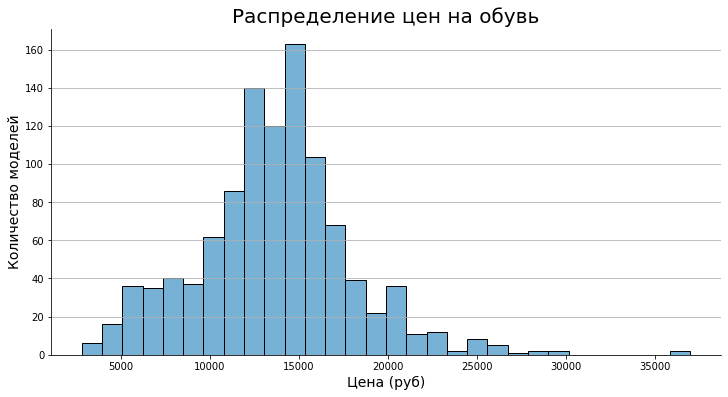

In [183]:
plt.figure(figsize=(12,6))
sns.histplot(df['price'], bins=30, color=middle_blue)
plt.title('Распределение цен на обувь', fontsize=20)
plt.xlabel('Цена (руб)', fontsize=14)
plt.ylabel('Количество моделей', fontsize=14)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y')
plt.show()

**Вывод:**  
Основная масса обуви стоит от 5 000 до 20 000 руб. Дальше хвост до 30 000 руб и выброс более 35 000 руб. Пик приходится на 12 000-15 000 руб.

In [184]:
df['price'].describe().round()

count     1055.0
mean     13610.0
std       4365.0
min       2799.0
25%      10999.0
50%      13499.0
75%      15999.0
max      36990.0
Name: price, dtype: float64

### 2.1.2. Цены по категориям

In [185]:
df.groupby('category')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Детская обувь,151.0,6925.509934,1739.841283,2799.0,5499.0,6999.0,7999.0,11290.0
Женская обувь,482.0,14422.228216,3387.654845,6290.0,11999.0,14290.0,16290.0,26999.0
Мужская обувь,422.0,15073.071090,3819.685746,6290.0,12999.0,14499.0,16499.0,36990.0


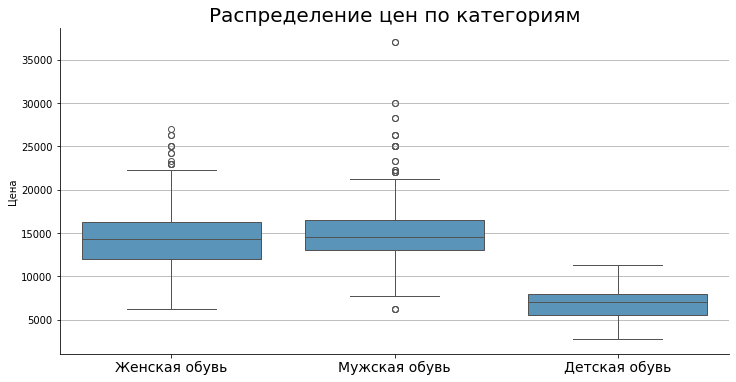

In [186]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='category', y='price', color=middle_blue)
plt.title('Распределение цен по категориям', fontsize=20)
plt.xlabel('')
plt.ylabel('Цена')
plt.xticks(fontsize=14)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y')
plt.show()

**Вывод:**  
Цены варьируются от 2 799 руб до 36 990 руб, средняя цена — 13 610 руб, медианная — 13 499 руб. Дороже всего мужская обувь (средняя цена — 15 073 руб). Средняя цена мужской обуви выше из‑за отдельных очень дорогих моделей. Типичные цены в категории мужской и женской обуви близки. Детская обувь дешевле взрослой. 

### 2.1.3. Цены по типу

In [187]:
df.groupby('type')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Балетки,14.0,9414.642857,4074.140808,3299.0,8496.75,9990.0,9990.00,17999.0
Босоножки,26.0,15371.423077,3068.047460,9799.0,12999.00,16290.0,16821.75,19990.0
Ботильоны,18.0,12249.000000,2116.114642,8999.0,9999.00,11999.0,13499.00,15499.0
Ботинки,142.0,12925.056338,2956.509337,4999.0,10999.00,12999.0,14999.00,21999.0
Дутики,2.0,10999.000000,1414.213562,9999.0,10499.00,10999.0,11499.00,11999.0
Кеды,188.0,13949.069149,3762.749011,5499.0,11999.00,13499.0,14999.00,29990.0
Кроссовки,279.0,15345.659498,5224.501465,4799.0,12499.00,14990.0,17999.00,36990.0
Лоферы,38.0,14171.526316,3282.443114,5499.0,12074.00,14894.5,16290.00,19990.0
Мокасины,8.0,13420.625000,2613.697487,10499.0,10874.00,13249.0,16290.00,16290.0


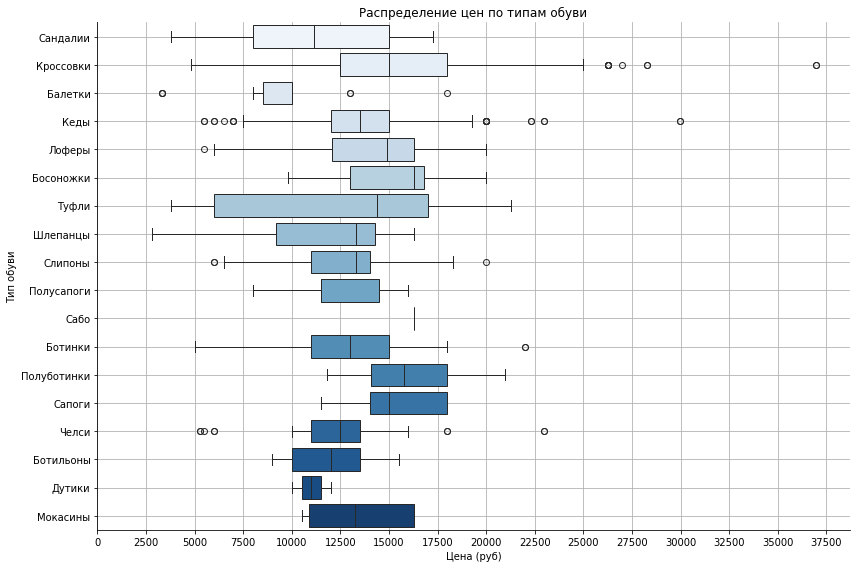

In [188]:
plt.figure(figsize=(12, 8))
sns.boxplot(data=df, y='type', x='price', hue='type', legend=False, palette='Blues')
plt.title('Распределение цен по типам обуви')
plt.xlabel('Цена (руб)')
plt.ylabel('Тип обуви')
plt.xticks([i for i in range(0, 40000, 2500)])
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y')
ax.grid(True, axis='x')
plt.tight_layout()
plt.show()

In [189]:
df.groupby('type')['price'].agg(['mean', 'median', 'count']).round().sort_values('median', ascending=False)

,mean,median,count
type,,,
Босоножки,15371.0,16290.0,26
Сабо,16290.0,16290.0,2
Полуботинки,15991.0,15749.0,30
Сапоги,15499.0,14999.0,11
Кроссовки,15346.0,14990.0,279
Лоферы,14172.0,14894.0,38
Туфли,12661.0,14399.0,56
Кеды,13949.0,13499.0,188
Слипоны,12445.0,13290.0,29


**Вывод:**  
- Самые дорогие типы обуви (по медиане): босоножки, сабо и полуботинки. 
- Самые дешевые (по медиане): сандалии, дутики и балетки.

In [190]:
df_pivot = pd.pivot_table(df, 
                          values='price', 
                          index='type', 
                          columns='category', 
                          aggfunc='median').round(2)
df_pivot_sorted = df_pivot.sort_values('Женская обувь', ascending=False)
df_pivot_sorted = df_pivot_sorted.fillna(0)
df_pivot_sorted

category,Детская обувь,Женская обувь,Мужская обувь
type,,,
Полуботинки,0.0,19990.0,14990.0
Босоножки,0.0,16290.0,0.0
Кроссовки,6999.0,16290.0,14999.0
Сабо,0.0,16290.0,0.0
Туфли,4799.0,14999.0,16144.5
Сапоги,0.0,14999.0,0.0
Сандалии,7999.0,14990.0,14290.0
Кеды,6999.0,13499.0,13499.0
Шлепанцы,2799.0,13290.0,13290.0


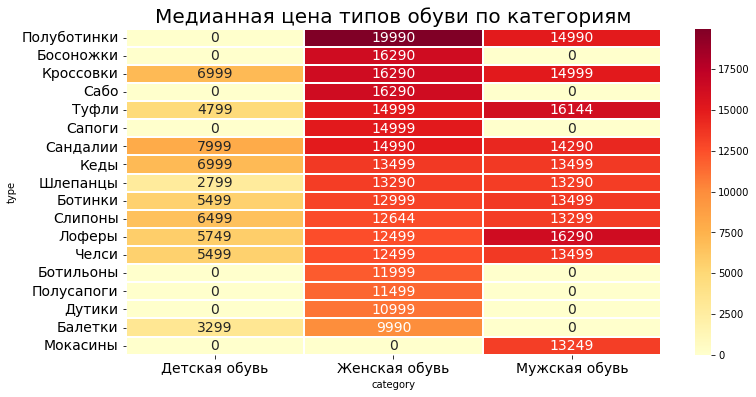

In [191]:
df_for_heatmap = df_pivot_sorted.astype(int)

plt.figure(figsize=(12,6))
sns.heatmap(df_for_heatmap, annot=True, annot_kws={'size': 14}, fmt='', cmap='YlOrRd', linewidths=0.1)
plt.xticks(fontsize=14)
plt.yticks(rotation=360, fontsize=14)
plt.title('Медианная цена типов обуви по категориям', fontsize=20)
plt.show()

**Вывод:**  
Медианные цены заметно различаются в зависимости от категории (женская, мужская, детская) и типа обуви.

1. Самые дорогие типы в женской категории — полуботинки, босоножки, кроссовки (медиана 16 000-20 000 руб).

2. В мужской категории самые дорогие — туфли, лоферы, кроссовки (около 16 000 руб).

3. В детской категории дороже всего — сандалии, кеды, кроссовки (7 000-8 000 руб).

Дешевые типы в женской категории — дутики, балетки (около 10 000 руб), в мужской — шлепанцы, слипоны (около 13 000 руб), в детской — балетки (около 3 300 руб).

In [192]:
df.sample(5)

,article,type,model,color,price,price_old,category,collection,sizes,discount,discount_percent,size_count,main_collection
755,501654.0,Слипоны,ECCO BYWAY,синий,9499,13290,Мужская обувь,"SS26, SS25","[40, 41, 42, 43, 44, 45, 46]",3791,28.5,7,SS26
475,222413.0,Ботильоны,ECCO SCULPTED LX 35,белый,13499,20990,Женская обувь,"AW25, AW24, AW23","[36, 37, 38, 39, 40, 41]",7491,35.7,6,AW25
1026,712172.0,Сандалии,ECCO SP.1 LITE SANDAL K,розовый,4999,8990,Детская обувь,"SS25, SS23","[27, 32, 33, 34, 35]",3991,44.4,5,SS25
359,238833.0,Шлепанцы,ECCO SOFT SANDAL W,коричневый,13290,0,Женская обувь,SS26,"[36, 37, 38, 39, 40, 41]",0,0.0,6,SS26
605,511824.0,Ботинки,ECCO ATH-1FTR M,черный,10999,19990,Мужская обувь,"AW25, AW24, AW22","[40, 41, 42, 43, 44, 45, 46]",8991,45.0,7,AW25


## 2.2. Скидки

### 2.2.1. Распределение скидок

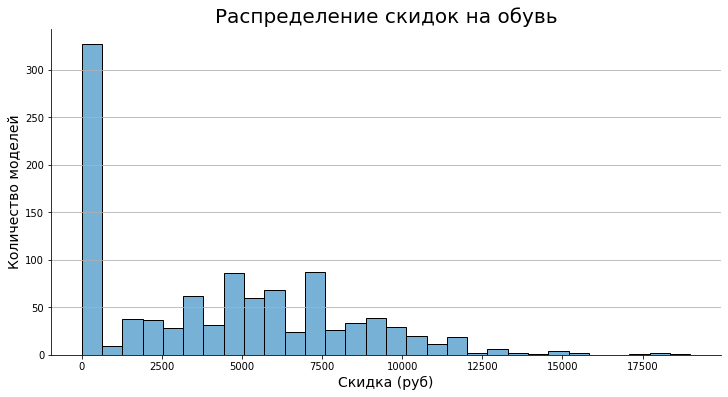

In [193]:
plt.figure(figsize=(12,6))
sns.histplot(df['discount'], bins=30, color=middle_blue)
plt.title('Распределение скидок на обувь', fontsize=20)
plt.xlabel('Скидка (руб)', fontsize=14)
plt.ylabel('Количество моделей', fontsize=14)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y')
plt.show()

In [194]:
df_disc = df[df['discount_percent'] > 0].copy()

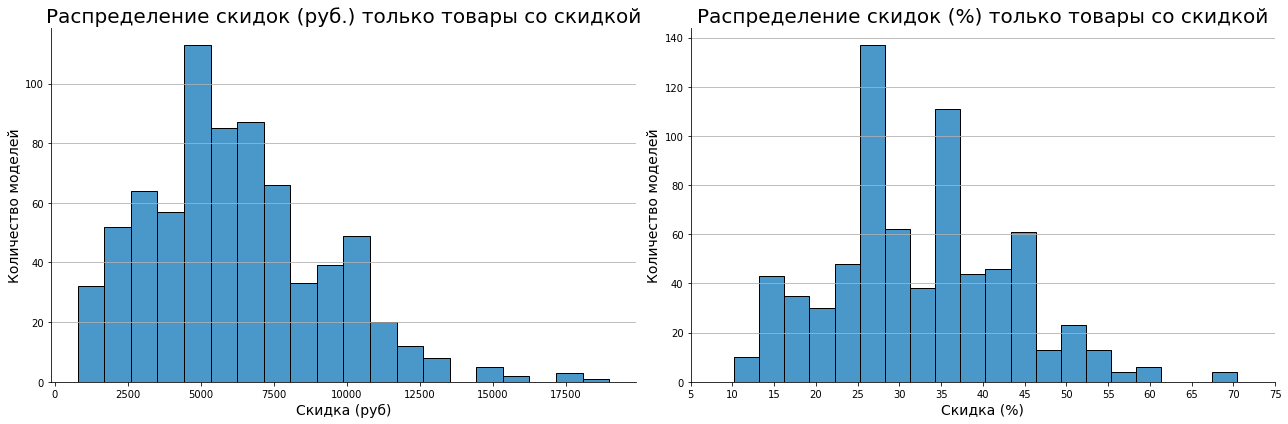

In [195]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

ax[0].hist(df_disc['discount'], bins=20, color=middle_blue, edgecolor='black')
ax[0].set_title('Распределение скидок (руб.) только товары со скидкой', fontsize=20)
ax[0].set_xlabel('Скидка (руб)', fontsize=14)
ax[0].set_ylabel('Количество моделей', fontsize=14)
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
ax[0].grid(True, axis='y')


ax[1].hist(df_disc['discount_percent'], bins=20, color=middle_blue, edgecolor='black')
ax[1].set_title('Распределение скидок (%) только товары со скидкой', fontsize=20)
ax[1].set_xlabel('Скидка (%)', fontsize=14)
ax[1].set_ylabel('Количество моделей', fontsize=14)
ax[1].set_xticks([i for i in range(5, 80, 5)])
ax[1].spines['top'].set_visible(False)
ax[1].spines['right'].set_visible(False)
ax[1].grid(True, axis='y')

plt.tight_layout()
plt.show()

**Вывод:**  
Большинство скидок в рублях — около 5 000 руб, в процентах около 25% и около 35%. Есть несколько моделей со скидкой 17 500 руб и более или 70%.

### 2.2.2. Скидки по категориям

In [196]:
df_disc.groupby('category')['discount_percent'].agg(['mean', 'median']).round(1).sort_values('mean', ascending=False)

,mean,median
category,,
Женская обувь,34.3,34.8
Мужская обувь,31.5,29.0
Детская обувь,29.2,28.8


In [197]:
df_disc.groupby('category')['discount'].agg(['mean', 'median']).round(1).sort_values('mean', ascending=False)

,mean,median
category,,
Женская обувь,7164.9,6991.0
Мужская обувь,6514.2,5991.0
Детская обувь,2677.4,2491.0


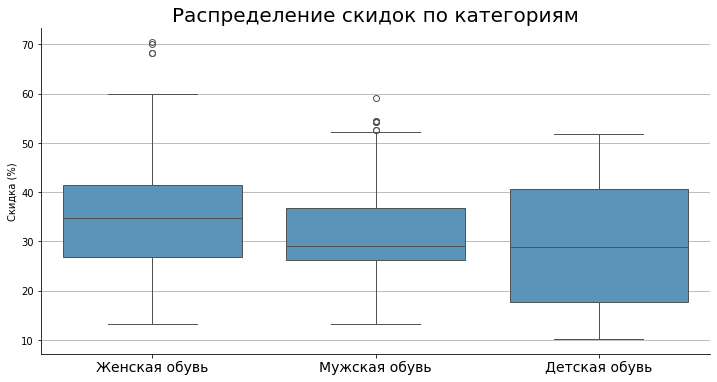

In [198]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_disc, x='category', y='discount_percent', color=middle_blue)
plt.title('Распределение скидок по категориям', fontsize=20)
plt.xlabel('')
plt.ylabel('Скидка (%)')
plt.xticks(fontsize=14)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y')
plt.show()

**Вывод:**  
Наибольшие скидки приходятся на женскую обувь (в среднем 7 165 руб и 34%). На мужскую и детскую обувь скидка ниже — около 30%.

### 2.2.3. Скидки по типу обуви

In [199]:
df_disc.groupby('type')['discount_percent'].describe().sort_values('count', ascending=False).round(2)

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Кроссовки,181.0,28.61,7.94,10.8,24.60,27.30,34.40,50.0
Кеды,145.0,28.81,9.38,11.0,22.20,27.50,35.00,59.1
Ботинки,142.0,40.54,9.22,15.6,35.00,38.75,45.70,70.0
Сандалии,59.0,25.51,11.44,10.2,13.90,24.60,35.50,45.7
Туфли,40.0,32.96,9.02,14.1,26.50,31.95,39.42,46.6
Челси,31.0,38.62,5.67,25.0,34.20,35.70,42.30,51.8
Лоферы,22.0,27.98,9.97,14.1,18.12,27.60,35.88,50.0
Слипоны,22.0,29.05,7.56,14.7,26.15,27.40,30.00,45.4
Ботильоны,18.0,46.32,9.45,34.1,37.10,42.80,56.00,60.0


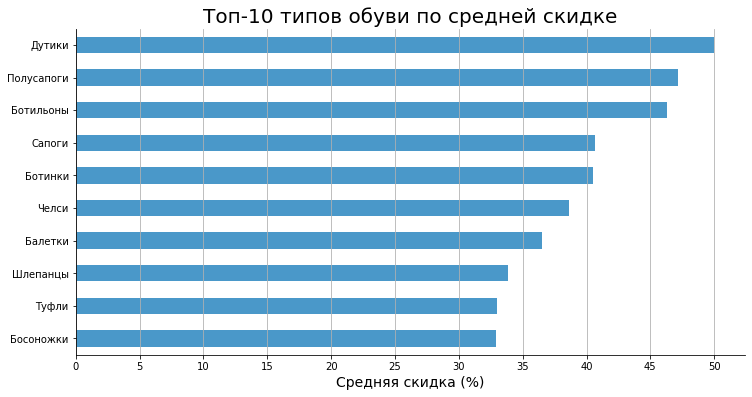

In [200]:
top10_discount = df_disc.groupby('type')['discount_percent'].mean().nlargest(10).sort_values()

plt.figure(figsize=(12, 6))
top10_discount.plot(kind='barh', color=middle_blue)
plt.title('Топ-10 типов обуви по средней скидке', fontsize=20)
plt.xlabel('Средняя скидка (%)', fontsize=14)
plt.ylabel('')
plt.xticks([i for i in range(0, 55, 5)])
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='x')
plt.show()

**Вывод:**  
Наибольшие скидки (в среднем более 40%) приходятся на осенне-зимние типы обуви: дутики, полусапоги, ботильоны, сапоги и ботинки. Это может быть связано с сезонным снижением цен на теплые модели после окончания зимнего сезона.

## 2.3. Типы и цвета

### 2.3.1. Распределение цветов

In [201]:
df['color'].value_counts()

color
черный                   374
коричневый               188
белый                    111
синий                     75
серый                     48
                        ... 
бирюзовый/голубой          1
белый/розовый/бежевый      1
белый/темно-красный        1
белый/темно-желтый         1
оранжевый/серый            1
Name: count, Length: 61, dtype: int64

In [202]:
def simplify_color(color):
    if '/' in color:
        return 'мультицвет'
    color = color.replace('светло-', '').replace('темно-', '').replace('св.', '')
    base_colors = ['белый', 'черный', 'серый', 'бежевый', 'коричневый', 'синий', 'розовый']
    if color in base_colors:
        return color
    else:
        return 'другой'

df['main_color'] = df['color'].apply(simplify_color)

In [203]:
len(df['main_color'].unique())

9

In [204]:
df['main_color'].value_counts()

main_color
черный        374
коричневый    195
другой        119
белый         111
синий          75
серый          51
мультицвет     50
бежевый        40
розовый        40
Name: count, dtype: int64

<ipython-input-205-a07e99a1178a>:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='main_color', order=df['main_color'].value_counts().index, edgecolor = 'black',


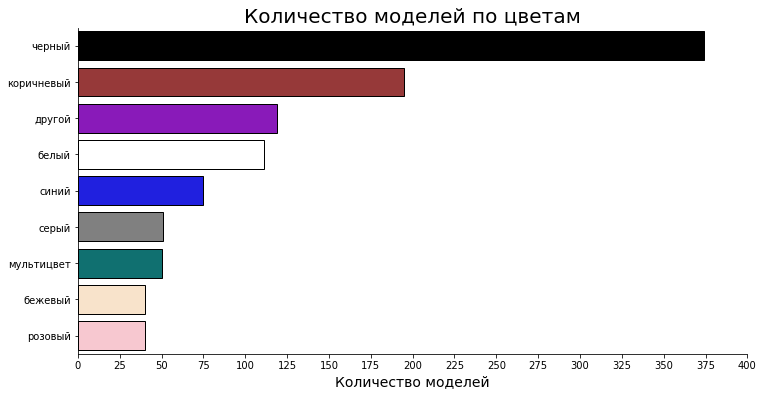

In [205]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, y='main_color', order=df['main_color'].value_counts().index, edgecolor = 'black', 
              palette=['black', 'brown', 'darkviolet', 'white', 'blue', 'gray', 'teal', 'bisque', 'pink'])
plt.xlabel('Количество моделей', fontsize=14)
plt.ylabel('')
plt.xticks([i for i in range(0, 425, 25)])
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.title('Количество моделей по цветам', fontsize=20)
plt.show()

**Вывод:**  
Самый популярный цвет обуви — черный (374 модели). Далее с большим отрывом следуют коричневый (195) и белый (111).

### 2.3.2. Цвета и цена

In [206]:
df.groupby('main_color')['price'].agg(['mean', 'median', 'count']).round(2).sort_values('mean', ascending=False)

,mean,median,count
main_color,,,
белый,15894.69,14990.0,111
бежевый,14492.00,14544.5,40
серый,14133.08,13999.0,51
мультицвет,14037.76,13299.0,50
коричневый,14035.57,13499.0,195
черный,13710.28,13999.0,374
другой,12150.14,12499.0,119
синий,11679.51,11999.0,75
розовый,10125.60,9149.0,40


**Вывод:**  
- Самая дорогая обувь — белого (средняя цена 15 895 руб), бежевого (14 492 руб) и серого (14 133 руб) цветов. 
- Самые дешевые цвета — синий (11 680 руб) и розовый (10 126 руб).

### 2.3.3. Цвета и цена по типу обуви

In [207]:
df_pivot_type = pd.pivot_table(df, 
                          values='price', 
                          index='type', 
                          columns='main_color', 
                          aggfunc='mean').round(2)
df_pivot_type = df_pivot_type.sort_values('черный', ascending=False)
df_pivot_type = df_pivot_type.fillna(0)
df_pivot_type

main_color,бежевый,белый,другой,коричневый,мультицвет,розовый,серый,синий,черный
type,,,,,,,,,
Сабо,0.00,16290.00,0.00,0.00,0.00,0.00,0.00,0.00,16290.00
Кроссовки,15395.40,17974.93,13598.12,16707.08,16517.22,9315.67,15899.40,11540.14,15715.64
Полуботинки,0.00,0.00,15262.67,16031.27,19990.00,0.00,15290.00,17990.00,15551.09
Босоножки,16290.00,14262.67,16444.50,17017.25,0.00,14499.00,0.00,9799.00,15202.83
Сапоги,0.00,0.00,0.00,16415.67,0.00,0.00,0.00,0.00,14399.00
Кеды,13605.08,14453.14,13875.64,13439.09,12199.00,13131.58,13370.43,14154.53,14317.56
Слипоны,18290.00,16994.50,6762.67,12917.20,0.00,0.00,10999.00,11072.88,13797.00
Лоферы,0.00,13249.00,14071.75,14921.36,0.00,0.00,0.00,15096.00,13683.89
Мокасины,0.00,0.00,0.00,13429.33,0.00,0.00,0.00,0.00,13415.40


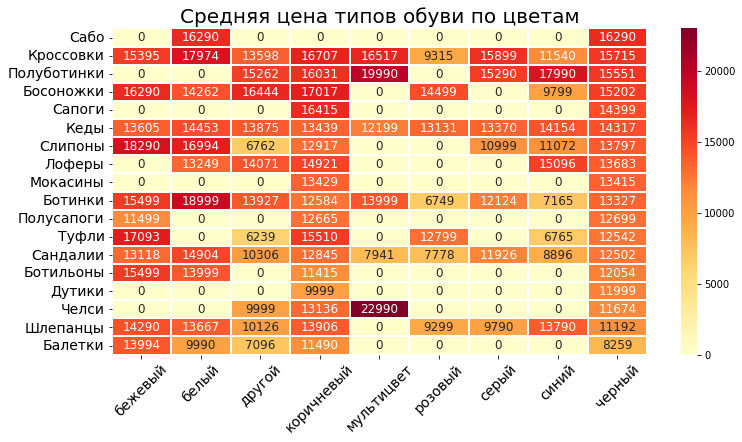

In [208]:
df_for_heatmap_type = df_pivot_type.astype(int)

plt.figure(figsize=(12,6))
sns.heatmap(df_for_heatmap_type, annot=True, annot_kws={'size': 12}, fmt='', cmap='YlOrRd', linewidths=0.1)
plt.xticks(rotation=45, fontsize=14)
plt.yticks(rotation=360, fontsize=14)
plt.xlabel('')
plt.ylabel('')
plt.title('Средняя цена типов обуви по цветам', fontsize=20)
plt.show()

**Вывод:**  
- Наиболее дорогие сочетания «тип обуви + цвет» — челси + мультицвет (22 990 руб), полуботинки + мультицвет (19 990 руб) и ботинки + белый (18 999 руб).  
- Дешевле всего — туфли + «другой» (6 239 руб), ботинки + розовый (6 749 руб) и слипоны + «другой» (6 762 руб).
- Самый богатый выбор цветов у кроссовок, кед, ботинок и сандалий.
- Меньше всего цветов у таких типов как: сабо, сапоги и мокасины.
- В черном цвете представлены все типы обуви. В коричневом все, кроме сабо.
- Многие сочетания отсутствуют (например, сапоги в бежевом или дутики в сером).

### 2.3.4. Цвета и цена по категориям

In [209]:
df_pivot_cat = pd.pivot_table(df, 
                          values='price', 
                          index='main_color', 
                          columns='category', 
                          aggfunc='mean').round(2)
df_pivot_cat = df_pivot_cat.sort_values('Детская обувь', ascending=False)
df_pivot_cat

category,Детская обувь,Женская обувь,Мужская обувь
main_color,,,
бежевый,8790.00,14971.17,14120.62
белый,7222.88,16075.14,17614.18
другой,7198.37,14586.81,15234.95
серый,7144.50,13371.78,14653.80
мультицвет,7050.08,15727.76,18086.92
коричневый,7015.40,13780.01,14520.35
синий,6852.42,13081.54,14248.55
черный,6653.32,14024.18,15067.10
розовый,6497.50,13103.55,12999.00


**Вывод:**  
- В женской обуви самые дорогие цвета — белый (16 075 руб) и мультицвет (15 727 руб), самые дешевые — розовый (13 103 руб) и синий (13 081 руб).
- В мужской обуви дороже всего — мультицвет (18 087 руб) и белый (17 615 руб), дешевле — бежевый (14 121 руб) и розовый (12 999 руб).
- В детской обуви цены ожидаемо ниже: самые дорогие цвета — бежевый (8 790 руб) и белый (7 223 руб), дешевый — розовый (6 497 руб).
- Во всех категориях белый цвет входит в число самых дорогих цветов, а розовый — в число самых дешевых.

### 2.3.5. Цвета и коллекция

In [210]:
df['main_collection'].value_counts()

main_collection
SS26    475
AW25    289
SS25    132
AW26    128
AW24     29
SS24      2
Name: count, dtype: int64

In [211]:
collection_color_counts = df.groupby(['main_collection', 'main_color']).size().reset_index(name='count')
top3_colors = collection_color_counts.sort_values(['main_collection', 'count'], ascending=[True, False]) \
                                      .groupby('main_collection').head(3)
top3_colors

,main_collection,main_color,count
6,AW24,черный,13
2,AW24,другой,6
3,AW24,коричневый,5
15,AW25,черный,132
10,AW25,коричневый,88
9,AW25,другой,21
23,AW26,черный,73
19,AW26,коричневый,25
22,AW26,синий,10
24,SS24,розовый,2


**Вывод:**  
В сезонах осень-зима (AW) преобладают темные цвета (черный и коричневый), в сезоне весна-лето 2025 года (SS25) самые популярные цвета черный и белый, а в 2026 году (SS26) — черный и коричневый. 

## 2.4. Размеры

### 2.4.1. Распределение размеров

In [212]:
sizes_expanded = df['sizes'].explode()

In [213]:
size_counts = sizes_expanded.value_counts().sort_index()
size_counts

sizes
22     16
23     17
24     17
25     17
26     17
27     55
28     56
29     55
30     70
31     73
32     74
33     75
34     74
35     90
36    371
37    496
38    501
39    513
40    843
41    789
42    437
43    384
44    371
45    367
46    327
47     37
48      5
Name: count, dtype: int64

In [214]:
size_counts.nlargest(3)

sizes
40    843
41    789
39    513
Name: count, dtype: int64

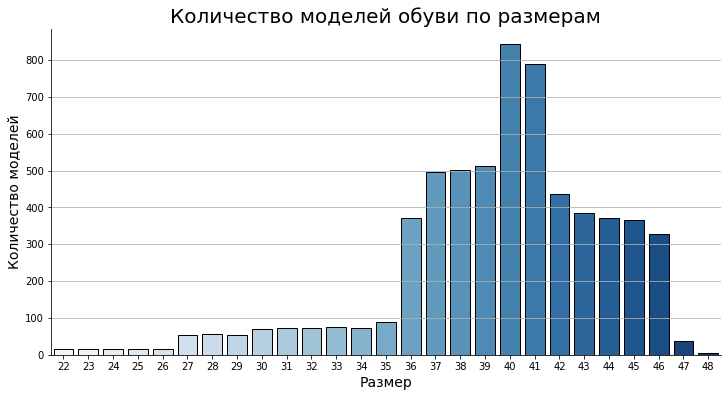

In [215]:
plt.figure(figsize=(12, 6))
sns.barplot(x=size_counts.index, y=size_counts.values, hue=size_counts.index, legend=False, edgecolor='black', palette='Blues')
plt.title('Количество моделей обуви по размерам', fontsize=20)
plt.xlabel('Размер', fontsize=14)
plt.ylabel('Количество моделей', fontsize=14)
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y')
plt.show()

In [216]:
df[['type', 'model', 'category', 'color', 'size_count']].sort_values('size_count', ascending=False).head(3)

,type,model,category,color,size_count
532,Шлепанцы,ECCO COZMO E,Мужская обувь,черный,11
1017,Сандалии,ECCO X-TRINSIC K,Детская обувь,розовый/каралловый,9
709,Туфли,ECCO METROPOLE LONDON,Мужская обувь,черный,9


**Вывод:**  
- Диапазон размеров: от 22 до 48.
- Больше всего моделей обуви представлено в следующих размерах: 40 (843 модели), 41 (789 моделей), 39 (513 моделей).
- Модель с самым широким размерным рядом — это мужские черные шлепанцы ECCO COZMO E (11 размеров).

### 2.4.2. Размеры по категориям

In [217]:
sizes_cat_expanded = df[['category', 'sizes']].explode('sizes')

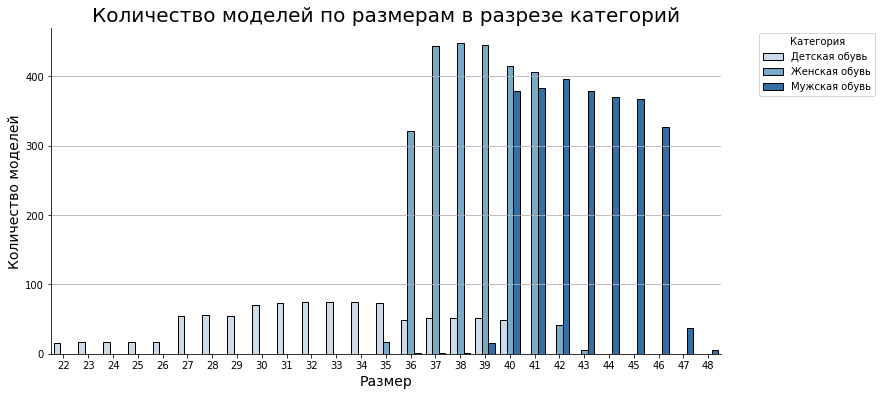

In [218]:
size_cat_counts = sizes_cat_expanded.groupby(['category', 'sizes']).size().reset_index(name='count')

plt.figure(figsize=(12, 6))
sns.barplot(data=size_cat_counts, x='sizes', y='count', hue='category', palette='Blues', edgecolor='black')
plt.title('Количество моделей по размерам в разрезе категорий', fontsize=20)
plt.xlabel('Размер', fontsize=14)
plt.ylabel('Количество моделей', fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Категория')
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y')
plt.show()

**Вывод:**  
- Разброс размеров в женской обуви от 35 до 43, в мужской — от 39 до 48, в детской обуви самый широкий размерный ряд от 22 до 40.
- В женской обуви самые популярные размеры 37-39, в мужской — 40-45, в детской — 30-35.

### 2.4.3. Размеры по типу

In [219]:
type_size_count = df.groupby('type')['size_count'].mean().sort_values(ascending=False).round(1)
type_size_count

type
Мокасины       6.5
Шлепанцы       6.4
Сандалии       6.2
Слипоны        6.1
Кеды           6.0
Челси          5.8
Ботинки        5.8
Лоферы         5.8
Полуботинки    5.7
Босоножки      5.7
Туфли          5.7
Кроссовки      5.7
Сабо           5.5
Дутики         5.5
Балетки        5.5
Полусапоги     5.2
Ботильоны      4.4
Сапоги         4.4
Name: size_count, dtype: float64

In [220]:
sizes_expanded = df[['type', 'sizes']].explode('sizes')

In [221]:
modal_size_per_type = sizes_expanded.groupby('type')['sizes'].agg(lambda x: x.mode()[0])
modal_size_per_type

type
Балетки        36
Босоножки      38
Ботильоны      39
Ботинки        40
Дутики         37
Кеды           40
Кроссовки      40
Лоферы         40
Мокасины       40
Полуботинки    41
Полусапоги     36
Сабо           37
Сандалии       40
Сапоги         41
Слипоны        40
Туфли          40
Челси          41
Шлепанцы       40
Name: sizes, dtype: object

**Вывод:**  
- Самый полный размерный ряд — у мокасин, шлепанцев, сандалий и слипонов (в среднем 6+ размеров на модель).  
- Типичный (наиболее часто встречающийся) размер: 36 — для балеток и полусапогов, 41 — для челси, полуботинок и сапогов.

## 2.5. Коллекции

### 2.5.1. Обзор коллекций

In [222]:
df_collections = df[['model', 'price', 'price_old', 'type', 'category', 'main_color', 'discount_percent', 'collection']].copy()
df_collections['collection'] = df_collections['collection'].str.split(',')
df_collections = df_collections.explode('collection')
df_collections['collection'] = df_collections['collection'].str.strip()

In [223]:
df_collections['collection'].value_counts().sort_values(ascending=False)

collection
SS26    554
AW25    492
SS25    378
AW24    250
SS24    151
AW23    130
AW26    128
SS23    101
AW22     86
SS22     65
AW21     51
SS21     40
SS20     31
AW20     29
SS19     23
AW19     22
SS18     17
AW18     16
AW16     11
AW17     10
SS17     10
AW15      7
SS16      5
SS09      3
SS10      3
SS11      3
SS12      3
AW07      2
AW09      2
SS14      2
SS15      1
AW14      1
SS13      1
Name: count, dtype: int64

In [224]:
df_collections.groupby('collection')['price'].mean().round(2).sort_values(ascending=False)

collection
SS16    16570.00
AW15    15808.14
SS17    15720.90
AW19    15620.95
SS19    15486.43
SS21    15263.40
SS18    15144.53
SS20    15068.58
AW18    15062.69
AW20    15031.34
AW17    15023.60
AW09    14990.00
SS13    14990.00
SS12    14990.00
SS11    14990.00
SS10    14990.00
SS09    14990.00
AW23    14759.32
SS23    14604.47
AW24    14535.31
SS24    14517.54
SS22    14343.12
AW26    14245.12
SS26    14175.65
SS25    14040.97
AW16    13876.73
AW22    13861.83
AW21    13752.51
AW25    13687.56
SS14    12994.50
AW07    12994.50
SS15    10999.00
AW14    10999.00
Name: price, dtype: float64

In [225]:
df_collections[df_collections['collection'] == 'AW07']['model'].unique()

array(['ECCO OFFROAD'], dtype=object)

**Вывод:**  
- Самые популярные коллекции — AW25, SS25, SS26 (больше 300 моделей в каждой).
- Самая дорогая коллекция SS16 (средняя цена более 16 500 руб).
- Мужские и женские сандалии ECCO OFFROAD представлены в ассортименте с коллекции AW07 (2007 год) и продолжают продаваться в новых сезонах.

### 2.5.2. Коллекции по категориям

In [226]:
df_collections.groupby(['collection', 'category'])['price'].mean().unstack().round(2)

category,Детская обувь,Женская обувь,Мужская обувь
collection,,,
AW07,NaN,12994.50,NaN
AW09,NaN,14990.00,14990.00
AW14,NaN,10999.00,NaN
AW15,NaN,15967.25,15596.00
AW16,NaN,13428.33,15894.50
AW17,NaN,14609.67,15644.50
AW18,NaN,13561.17,15963.60
AW19,NaN,15393.38,15751.00
AW20,6290.00,14993.60,15537.94


**Вывод:**  
Самая высокая средняя цена в категории женская обувь в коллекции SS16 (16 965 руб), в мужской обуви — в коллекции SS17 (16 640 руб), в детской обуви — SS21 (8 093 руб).

### 2.5.3. Коллекции по типу

In [227]:
type_counts = df_collections.groupby(['collection', 'type']).size().reset_index(name='count')
top_type_per_collection = type_counts.sort_values('count', ascending=False).groupby('collection').first().reset_index()
top_type_per_collection[['collection', 'type']]

,collection,type
0,AW07,Сандалии
1,AW09,Сандалии
2,AW14,Туфли
3,AW15,Кеды
4,AW16,Кеды
5,AW17,Кеды
6,AW18,Кеды
7,AW19,Кеды
8,AW20,Кеды
9,AW21,Ботинки


**Вывод:**  
Самые старые «долгожители» в ассортименте — сандалии (продаются с коллекций AW07 и SS09). С середины 2010‑х годов к ним добавились кеды, а в последние годы лидером по числу новых моделей стали кроссовки.

### 2.5.4. Коллекции и скидки

In [228]:
df_col_per = df_collections.groupby('collection')['discount_percent'].mean().round(2).\
             sort_values(ascending=False).head(10).reset_index()
df_col_per

,collection,discount_percent
0,AW25,28.34
1,AW24,27.98
2,SS15,26.60
3,AW14,26.60
4,AW21,25.34
5,AW22,24.42
6,AW23,23.17
7,AW26,21.78
8,SS25,19.79
9,AW16,19.29


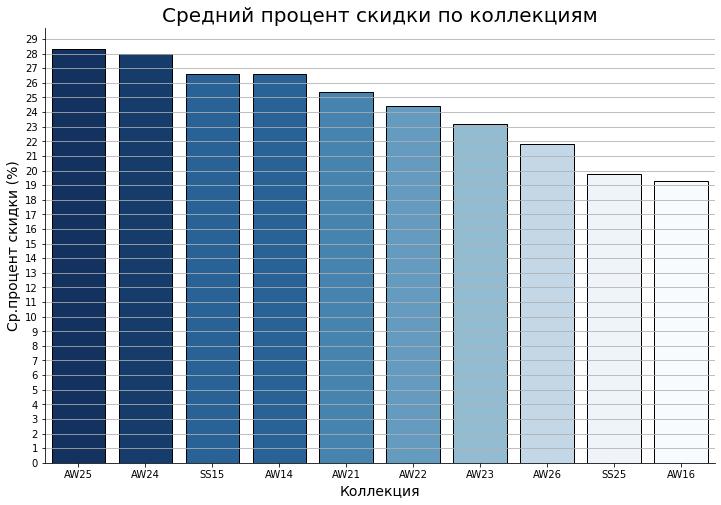

In [229]:
plt.figure(figsize=(12, 8))
sns.barplot(data=df_col_per, x='collection', y='discount_percent', hue='discount_percent', legend=False, edgecolor='black', palette='Blues')
plt.title('Средний процент скидки по коллекциям', fontsize=20)
plt.xlabel('Коллекция', fontsize=14)
plt.ylabel('Ср.процент скидки (%)', fontsize=14)
plt.yticks([i for i in range(0, 30)])
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='y')
plt.show()

In [230]:
df_collections.groupby('collection')['discount_percent'].max().sort_values(ascending=False).head(10)

collection
AW23    70.4
AW25    70.4
AW24    70.4
AW21    70.0
AW22    70.0
SS22    50.0
SS23    50.0
SS24    50.0
AW26    50.0
SS26    50.0
Name: discount_percent, dtype: float64

In [231]:
df_collections[df_collections['discount_percent'] > 0]['collection'].value_counts().head(10)

collection
AW25    400
SS25    252
SS26    250
AW24    192
AW26     95
AW23     79
SS24     62
AW22     53
AW21     32
SS23     29
Name: count, dtype: int64

**Вывод:**  
- Самые большие максимальные скидки (70% и выше) на коллекции AW21-AW25.
- Самые большие средние скидки (25-28%) на коллекции AW25, AW24, SS15, AW14, AW21.
- Больше всего моделей со скидками в коллекции AW25 (400 моделей).

# 3. Проверка гипотез

## 3.1. Гипотеза №1. Кроссовки

**Самый распространенный тип обуви - кроссовки.**

In [232]:
top_types = df['type'].value_counts().head(10)
print(top_types)

type
Кроссовки      279
Кеды           188
Ботинки        142
Сандалии       138
Туфли           56
Лоферы          38
Челси           33
Шлепанцы        32
Полуботинки     30
Слипоны         29
Name: count, dtype: int64


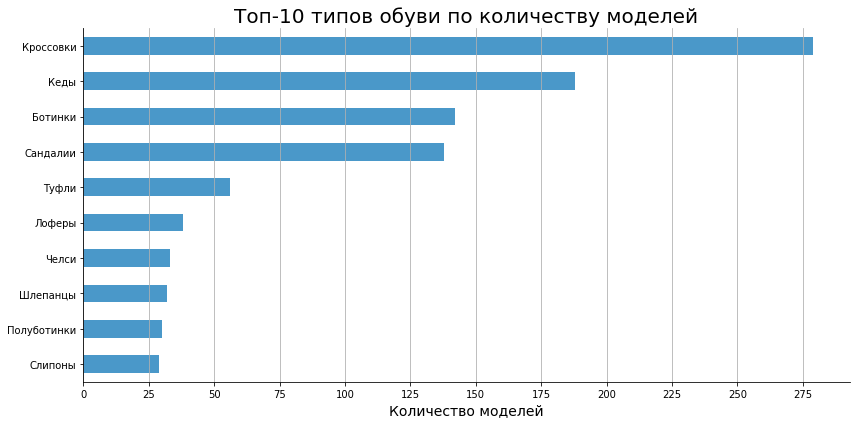

In [233]:
plt.figure(figsize=(12,6))
top_types.sort_values().plot(kind='barh', color=middle_blue)
plt.title('Топ-10 типов обуви по количеству моделей', fontsize=20)
plt.xlabel('Количество моделей', fontsize=14)
plt.ylabel('')
plt.xticks([i for i in range(0, 300, 25)])
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(True, axis='x')
plt.tight_layout()
plt.show()

**Гипотеза №1 (подтвердилась)**  
Самый распространенный тип обуви — кроссовки. Их представлено 279 моделей.

## 3.2. Гипотеза №2. Белые и черные кроссовки

**Белые кроссовки стоят дороже черных.**

In [234]:
df[(df['type'] == 'Кроссовки') & (df['main_color'] == 'черный')]['price'].mean().round(2)

15715.64

In [235]:
df[(df['type'] == 'Кроссовки') & (df['main_color'] == 'белый')]['price'].mean().round(2)

17974.93

**Гипотеза №2 (подтвердилась)**  
Средняя цена белых кроссовок (17 975 руб) выше средней цены черных кроссовк (15 716 руб). Это связано с тем, что обувь белого цвета дороже (п.2.3.4.).

## 3.3. Гипотеза №3. Процент скидки и цвет 

**Процент скидки на черную обувь выше, чем на белую.**

In [236]:
df[df['main_color'] == 'черный']['discount_percent'].mean().round(2)

24.1

In [237]:
df[df['main_color'] == 'белый']['discount_percent'].mean().round(2)

17.74

**Гипотеза №3 (подтвердилась)**  
Средний процент скидки на черную обувь (24,1%) выше, чем на белую обувь (17,74%).

## 3.4. Гипотеза №4. Мужские и женские ботинки

**Мужские ботинки стоят дороже, чем женские.**

In [238]:
df[(df['type'] == 'Ботинки') & (df['category'] == 'Мужская обувь')]['price'].mean().round(2)

13756.81

In [239]:
df[(df['type'] == 'Ботинки') & (df['category'] == 'Женская обувь')]['price'].mean().round(2)

12649.68

**Гипотеза №4 (подтвердилась)**  
Средняя цена на мужские ботинки (13 757 руб) выше, чем на женские ботинки (12 650 руб).

## 3.5. Гипотеза №5. Босоножки SS26 и SS25

**Босоножки новой коллекции (SS26) дороже босоножек прошлогодней коллекции (SS25).**

In [240]:
df[(df['type'] == 'Босоножки') & (df['main_collection'] == 'SS26')]['price'].mean().round(2)

17047.79

In [241]:
df[(df['type'] == 'Босоножки') & (df['main_collection'] == 'SS25')]['price'].mean().round(2)

13680.82

**Гипотеза №5 (подтвердилась)**  
Средняя цена босоножек коллекции весна-лето 2026 (17 048 руб) выше, чем средняя цена босоножек коллекции весна-лето 2025 года (13 681 руб). 

# 4. Общие выводы

## 4.1. Структура ассортимента и цены

- **Топ-3 типа обуви по популярности:** кроссовки (279 моделей), кеды (188), ботинки (142).
- **Диапазон цен:** от 2 800 руб (детская обувь) до 37 000 руб (мужская обувь). Средняя цена около 13 600 руб, медианная около 13 500 руб.
- **Самая дорогая категория:** мужская обувь (средняя цена 15 073 руб), но типичные цены мужской и женской обуви близки. Детская обувь закономерно дешевле взрослой.
- **Самый дорогой тип обуви (по медиане):** босоножки, сабо, полуботинки (15 750-16 300 руб).
- **Самый дешевый:** балетки, дутики, сандалии (9 990-11 150 руб).

## 4.2. Сезонные и цветовые тренды

- **Цвет:** лидер — черный (374 модели), далее коричневый и белый. Белый и бежевый цвета в среднем дороже, розовый и синий — дешевле.
- **Коллекции:** лидеры по числу моделей — AW25 (осень-зима 2025) и SS26 (весна-лето 2026). Самая дорогая коллекция — SS16, но в ней представлено всего 5 моделей.
- **Долгожители:** сандалии ECCO OFFROAD продаются с 2007-2009 годов.

## 4.3. Скидки

- **Типичная скидка:** около 5 000 руб или 25-35%. Максимальная достигает 70%.
- **Самые высокие скидки:** на женскую обувь (средняя скидка 34% против 29-31% у мужской и детской). 
- **Наибольшие средние и максимальные скидки:** на осенне-зимние коллекции (AW21-AW25), вероятно, в рамках сезонных распродаж.

## 4.4. Размеры

- **Диапазон размеров:** от 22 до 48 размера.
- **Самые ходовые размеры:** для взрослых — 40, 41; для детей — 30–35.
- **Самый полный размерный ряд (в среднем):** у мокасин, шлепанцев, сандалий, слипонов и кед (более 6 размеров на модель).

## 4.5. Проверка гипотез

**1.** Кроссовки — самый популярный тип обуви.  
**2.** Белые кроссовки дороже черных (17 975 руб против 15 716 руб).  
**3.** На черную обувь скидки выше, чем на белую (24% против 18%).  
**4.** Мужские ботинки дороже женских (13 757 руб против 12 650 руб).  
**5.** Босоножки новой коллекции (SS26) дороже прошлогодних (SS25) (17 048 руб против 13 681 руб).